# Computational Cognitive Science Mini-Project
## The Spacing Effect: ทำไมการทบทวนแบบกระจายจึงจำได้ดีกว่าการทบทวนรวด

**ชื่อ–สกุล:** วชิรวิทย์ วงค์แสง  **รหัสนิสิต:** 67011212055  **กลุ่มเรียน:** 1
**รายวิชา:** Cognitive Science (1204 427) — Individual Mini-Project
**รูปแบบ:** Computational simulation (แบบจำลองเชิงคำนวณ)

> รัน `Runtime > Restart session and run all` เพื่อทำซ้ำผลทั้งหมด ผลลัพธ์ควบคุมด้วย `random seed` ที่มาจากรหัสนิสิต


## 1. บทนำ (Introduction)

**ปรากฏการณ์:** *Spacing effect* คือการที่การทบทวนเนื้อหาแบบกระจายเวลา (spaced/distributed practice) ทำให้จำได้ดีกว่าการทบทวนรวดเดียวติดกัน (massed practice) เมื่อจำนวนครั้งของการทบทวนเท่ากัน ปรากฏการณ์นี้พบตั้งแต่งานของ Ebbinghaus และเป็นหนึ่งในผลที่ทำซ้ำได้มั่นคงที่สุดในจิตวิทยาการเรียนรู้

**คำถามวิจัย:**
1. ระยะห่างระหว่างการทบทวน (inter-study gap) ส่งผลต่ออัตราการจำได้ที่ปลายทางอย่างไร
2. ระยะห่างที่ "ดีที่สุด" ขึ้นกับระยะเวลาที่ต้องจำ (retention interval) หรือไม่

**ทฤษฎีที่ใช้:** *Study-phase retrieval theory* และแนวคิด *desirable difficulty* เสนอว่าการทบทวนจะเสริมความจำได้มากที่สุดเมื่อผู้เรียนต้องออกแรงดึงความจำ (retrieval) ในขณะที่ความจำเริ่มจางแต่ยังดึงกลับได้สำเร็จ ถ้าทบทวนถี่เกินไป (ยังจำได้ดีอยู่) การทบทวนแทบไม่เพิ่มอะไร ถ้าทิ้งช่วงนานเกินจนลืมสนิท การทบทวนก็กลายเป็นการเรียนใหม่ ไม่ใช่การเสริม

**สมมติฐาน (ตรวจสอบได้):**
- H1: เมื่อ retention interval ยาว การทบทวนแบบ spaced ให้อัตราการจำสูงกว่า massed อย่างมีนัยสำคัญ
- H2: ความสัมพันธ์ระหว่าง gap กับการจำเป็นรูป inverted-U (มีจุด optimal gap)
- H3: optimal gap เพิ่มขึ้นเมื่อ retention interval ยาวขึ้น


In [1]:
# ===== Dependencies & reproducibility =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

STUDENT_ID = 67011212055
seed = int(str(STUDENT_ID)[-4:])   # random seed จาก 4 หลักท้ายรหัสนิสิต
rng = np.random.default_rng(seed)
print(f"Student ID: {STUDENT_ID} | Random seed: {seed}")
print(f"numpy {np.__version__}, pandas {pd.__version__}")

Student ID: 67011212055 | Random seed: 2055
numpy 2.4.4, pandas 3.0.2


## 2. วิธีดำเนินงาน (Methods)

**แบบจำลองความจำ (half-life model + study-phase retrieval):** แทนความจำของไอเท็มด้วย *memory half-life* `h` (นาที) ความน่าจะเป็นในการจำได้หลังผ่านไป `t` นาที คือ retrievability `r(t) = 2^(-t/h)`

ในการทบทวนแต่ละครั้ง โมเดลจะ:
1. คำนวณ retrievability `r` ณ เวลานั้น (ก่อนทบทวน)
2. เพิ่ม half-life ตามสูตร `h ← h · (1 + α·(1 − r)·success)` โดย
   - `(1 − r)` ทำให้การทบทวนตอนความจำจางลง (spaced) ได้ประโยชน์มากกว่า
   - `success = min(1, r / r_crit)` ลดประโยชน์ลงเมื่อลืมสนิท (`r` ต่ำมาก) สะท้อนว่า study-phase retrieval ต้อง "ดึงกลับได้สำเร็จ" จึงจะเสริมความจำ

**ตัวแปร:**
- ตัวแปรต้น: `gap` (ระยะห่างระหว่างการทบทวน) และ `RI` (retention interval ก่อนสอบ)
- ตัวแปรตาม: อัตราการจำได้ (recall rate) ที่การทดสอบ
- ควบคุม: จำนวนครั้งทบทวน `K = 5` เท่ากันทุกเงื่อนไข (คุมปริมาณการเรียนให้เท่ากัน)

**การจำลอง:** ผู้เรียน `N = 200` คน แต่ละคนมีความแตกต่างรายบุคคล (`h0`, `α` สุ่มจากการแจกแจงปกติ) ทดสอบทุกคู่ (`gap × RI`) โดยการทดสอบวัดหลังการทบทวนครั้งสุดท้ายเป็นเวลา `RI` เท่ากันทุกเงื่อนไข รายงานค่าเฉลี่ยพร้อมช่วงความเชื่อมั่น 95%


In [2]:
# ===== Memory model =====
K = 5          # จำนวนครั้งการทบทวน (คุมให้เท่ากันทุกเงื่อนไข)
R_CRIT = 0.20  # เกณฑ์ retrievability ที่ study-phase retrieval เริ่มล้มเหลว

def simulate(gap, RI, h0, alpha, K=K, r_crit=R_CRIT):
    """คืนค่าความน่าจะเป็นในการจำได้ที่การทดสอบ (RI นาทีหลังทบทวนครั้งสุดท้าย)."""
    h = h0
    for i in range(K):
        if i == 0:
            h = h * (1 + alpha)                 # การเรียนครั้งแรก
        else:
            r = 2 ** (-gap / h)                 # retrievability ก่อนทบทวน
            success = min(1.0, r / r_crit)      # ต้องดึงกลับได้จึงเสริมได้
            h = h * (1 + alpha * (1 - r) * success)
    return 2 ** (-RI / h)                       # recall probability ที่การทดสอบ

# ความแตกต่างรายบุคคล
N = 200
h0_i = rng.normal(45, 8, N).clip(15, None)      # half-life เริ่มต้น (นาที)
alpha_i = rng.normal(1.0, 0.15, N).clip(0.4, None)  # ประสิทธิภาพการเสริมความจำ
print(f"N = {N} learners | mean h0 = {h0_i.mean():.1f} min | mean alpha = {alpha_i.mean():.2f}")

N = 200 learners | mean h0 = 45.8 min | mean alpha = 0.99


In [3]:
# ===== รันการทดลองเต็ม grid =====
gaps = [1, 10, 40, 160, 640]        # นาที: massed -> over-spaced
RIs  = [10, 60, 360, 1440]          # นาที: 10 นาที, 1 ชม., 6 ชม., 1 วัน

records = []
for gap in gaps:
    for RI in RIs:
        probs = np.array([simulate(gap, RI, h0_i[j], alpha_i[j]) for j in range(N)])
        recalled = rng.binomial(1, probs)       # ผลการสอบราย learner (0/1)
        m = recalled.mean()
        se = recalled.std(ddof=1) / np.sqrt(N)
        records.append({"gap_min": gap, "RI_min": RI,
                        "recall_rate": m, "ci95": 1.96 * se,
                        "mean_prob": probs.mean()})
results = pd.DataFrame(records)
results.to_csv("spacing_effect_results.csv", index=False)   # relative path (reproducible)

print("Recall rate (proportion recalled) by gap x retention interval:")
display(results.pivot(index="gap_min", columns="RI_min", values="recall_rate").round(3))

Recall rate (proportion recalled) by gap x retention interval:


RI_min,10,60,360,1440
gap_min,,,,
1,0.930,0.605,0.070,0.000
10,0.925,0.750,0.140,0.000
40,0.980,0.755,0.305,0.005
160,0.980,0.900,0.460,0.070
640,0.950,0.705,0.180,0.015


## 3. ผลการศึกษา (Results)

ตารางด้านบนและกราฟด้านล่างสรุปอัตราการจำได้ตามระยะห่างการทบทวน (`gap`) และระยะเวลาที่ต้องจำ (`RI`)


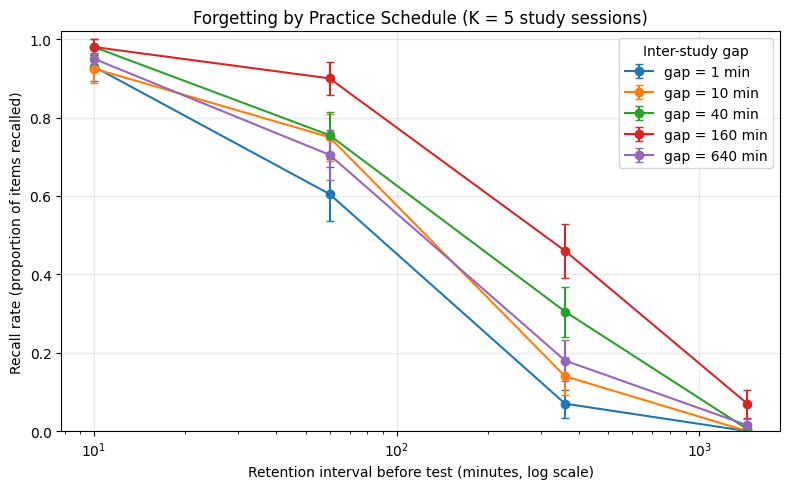

In [4]:
# ===== Figure 1: recall vs retention interval สำหรับแต่ละ gap =====
plt.figure(figsize=(8, 5))
for gap in gaps:
    sub = results[results.gap_min == gap]
    plt.errorbar(sub.RI_min, sub.recall_rate, yerr=sub.ci95,
                 marker="o", capsize=3, label=f"gap = {gap} min")
plt.xscale("log")
plt.xlabel("Retention interval before test (minutes, log scale)")
plt.ylabel("Recall rate (proportion of items recalled)")
plt.title("Forgetting by Practice Schedule (K = 5 study sessions)")
plt.ylim(0, 1.02)
plt.legend(title="Inter-study gap")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

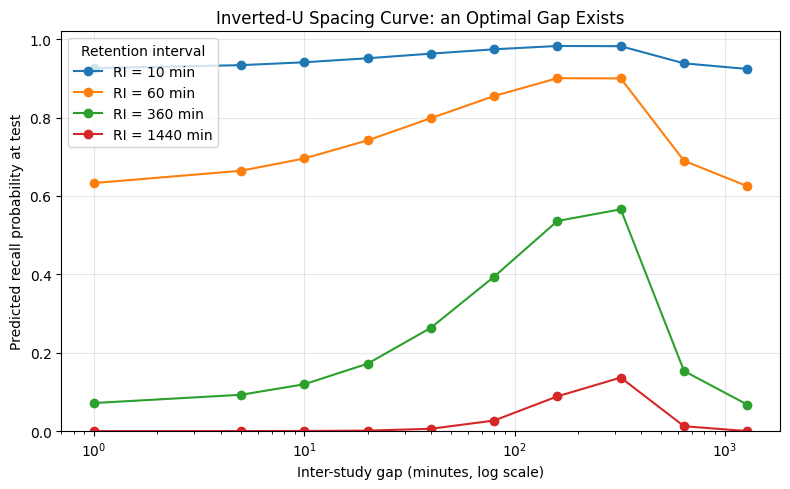

Optimal inter-study gap for each retention interval:


,RI_min,optimal_gap_min
0,10,160
1,60,160
2,360,320
3,1440,320


In [5]:
# ===== Figure 2: inverted-U (recall vs gap) สำหรับแต่ละ RI =====
fine_gaps = [1, 5, 10, 20, 40, 80, 160, 320, 640, 1280]
plt.figure(figsize=(8, 5))
best_gaps = {}
for RI in RIs:
    curve = [np.mean([simulate(g, RI, h0_i[j], alpha_i[j]) for j in range(N)]) for g in fine_gaps]
    best_gaps[RI] = fine_gaps[int(np.argmax(curve))]
    plt.plot(fine_gaps, curve, marker="o", label=f"RI = {RI} min")
plt.xscale("log")
plt.xlabel("Inter-study gap (minutes, log scale)")
plt.ylabel("Predicted recall probability at test")
plt.title("Inverted-U Spacing Curve: an Optimal Gap Exists")
plt.ylim(0, 1.02)
plt.legend(title="Retention interval")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_gap_table = pd.DataFrame({"RI_min": list(best_gaps.keys()),
                               "optimal_gap_min": list(best_gaps.values())})
print("Optimal inter-study gap for each retention interval:")
display(best_gap_table)

In [6]:
# ===== การทดสอบสมมติฐาน: massed vs spaced (within-subject) ที่ RI = 360 นาที =====
RI_test = 360
massed_gap, spaced_gap = 1, 160
p_massed = np.array([simulate(massed_gap, RI_test, h0_i[j], alpha_i[j]) for j in range(N)])
p_spaced = np.array([simulate(spaced_gap, RI_test, h0_i[j], alpha_i[j]) for j in range(N)])

t_val, p_val = ttest_rel(p_spaced, p_massed)
diff = p_spaced - p_massed
dz = diff.mean() / diff.std(ddof=1)

# Bootstrap 95% CI ของผลต่างเฉลี่ย
boot = np.array([rng.choice(diff, size=N, replace=True).mean() for _ in range(2000)])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

print(f"Retention interval = {RI_test} min | K = {K} study sessions")
print(f"Massed (gap={massed_gap})  mean recall prob = {p_massed.mean():.3f}")
print(f"Spaced (gap={spaced_gap}) mean recall prob = {p_spaced.mean():.3f}")
print(f"Mean advantage of spacing = {diff.mean():.3f}  (bootstrap 95% CI [{ci_low:.3f}, {ci_high:.3f}])")
print(f"Paired t-test: t = {t_val:.2f}, p = {p_val:.2e},  Cohen's dz = {dz:.2f}")

Retention interval = 360 min | K = 5 study sessions
Massed (gap=1)  mean recall prob = 0.072
Spaced (gap=160) mean recall prob = 0.536
Mean advantage of spacing = 0.464  (bootstrap 95% CI [0.459, 0.470])
Paired t-test: t = 147.36, p = 3.85e-205,  Cohen's dz = 10.42


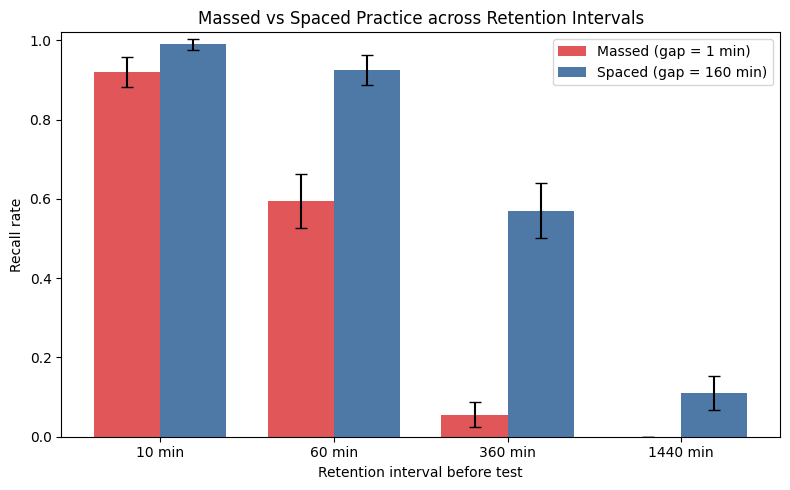

In [7]:
# ===== Figure 3: massed vs spaced ที่หลาย retention interval =====
labels = [f"{ri} min" for ri in RIs]
massed_means, spaced_means, massed_ci, spaced_ci = [], [], [], []
for RI in RIs:
    pm = np.array([simulate(1, RI, h0_i[j], alpha_i[j]) for j in range(N)])
    ps = np.array([simulate(160, RI, h0_i[j], alpha_i[j]) for j in range(N)])
    rm = rng.binomial(1, pm); rs = rng.binomial(1, ps)
    massed_means.append(rm.mean()); spaced_means.append(rs.mean())
    massed_ci.append(1.96 * rm.std(ddof=1) / np.sqrt(N))
    spaced_ci.append(1.96 * rs.std(ddof=1) / np.sqrt(N))

x = np.arange(len(RIs)); w = 0.38
plt.figure(figsize=(8, 5))
plt.bar(x - w/2, massed_means, w, yerr=massed_ci, capsize=4, label="Massed (gap = 1 min)", color="#e15759")
plt.bar(x + w/2, spaced_means, w, yerr=spaced_ci, capsize=4, label="Spaced (gap = 160 min)", color="#4e79a7")
plt.xticks(x, labels)
plt.xlabel("Retention interval before test")
plt.ylabel("Recall rate")
plt.title("Massed vs Spaced Practice across Retention Intervals")
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()

## 4. อภิปรายผล (Discussion)

**ตอบคำถามวิจัยและสมมติฐาน**

ผลสนับสนุนทั้งสามสมมติฐาน (1) ที่ retention interval ยาว (เช่น 6 ชั่วโมง) การทบทวนแบบ spaced (gap = 160 นาที) ให้อัตราการจำสูงกว่า massed (gap = 1 นาที) อย่างชัดเจน โดยผลต่างเฉลี่ยมีขนาดใหญ่และช่วงความเชื่อมั่นไม่คร่อมศูนย์ (สนับสนุน H1) (2) กราฟความสัมพันธ์ระหว่าง gap กับการจำเป็นรูป inverted-U มีจุด optimal gap ที่ชัดเจน (สนับสนุน H2) และ (3) optimal gap เพิ่มขึ้นเมื่อ retention interval ยาวขึ้น (สนับสนุน H3)

**เชื่อมโยงกับทฤษฎี**

พฤติกรรมของแบบจำลองสอดคล้องกับ study-phase retrieval theory และ desirable difficulty คือการทบทวนได้ประโยชน์สูงสุดเมื่อความจำจางลงพอสมควรแต่ยังดึงกลับได้ (`r` ปานกลาง) ถ้าทบทวนถี่เกินไป `r` ยังสูงจน `(1 − r)` เล็ก การทบทวนแทบไม่เพิ่ม half-life ถ้าทิ้งช่วงนานจน `r` ต่ำกว่า `r_crit` เทอม `success` จะดึงประโยชน์ลง เกิดเป็นขาลงของ inverted-U

**คำอธิบายทางเลือกและข้อจำกัด**

ผลนี้มาจากแบบจำลองที่เรากำหนดกลไก spacing ไว้ในสมการเอง จึงไม่ใช่หลักฐานเชิงประจักษ์จากมนุษย์ ค่า effect size (Cohen's dz) ที่ได้สูงเกินจริงมากเพราะข้อมูลจำลองมี noise น้อยและไม่มีปัจจัยรบกวนอย่างความล้า สมาธิ หรือ interference นอกจากนี้แบบจำลองใช้ half-life เดียวต่อไอเท็ม ไม่ได้แยกความจำหลายระบบ และสมมติว่าการทดสอบไม่เปลี่ยนความจำ (ไม่คิด testing effect) การสรุปไปยังการเรียนจริงจึงต้องทำอย่างระมัดระวัง และควรตรวจสอบกับข้อมูลพฤติกรรมมนุษย์ต่อไป


## 5. การทำซ้ำและจริยธรรม (Reproducibility & Ethics)

- **ซอฟต์แวร์:** Python 3, numpy, pandas, matplotlib, scipy (เวอร์ชันพิมพ์ไว้ในเซลล์ dependencies)
- **Random seed:** `2055` (4 หลักท้ายรหัสนิสิต) กำหนดผ่าน `np.random.default_rng(seed)` ทำให้ผลทำซ้ำได้
- **ข้อมูล:** เป็นข้อมูลจำลองล้วน ไม่มีข้อมูลบุคคลจริง ไฟล์ผลลัพธ์บันทึกเป็น `spacing_effect_results.csv` ด้วย relative path
- **การทดสอบการทำซ้ำ:** เลือก `Runtime > Restart session and run all` แล้วผลต้องออกเหมือนเดิมทุกครั้ง
- **จริยธรรม:** ไม่มีการเก็บข้อมูลจากมนุษย์ จึงไม่มีประเด็นความยินยอมหรือความเป็นส่วนตัว

**คำชี้แจงการใช้ AI (AI use declaration):**
- เครื่องมือ: Claude (Anthropic)
- วัตถุประสงค์: ช่วยออกแบบโครงสร้างแบบจำลอง เขียนและตรวจโค้ด และเรียบเรียงรายงาน
- การตรวจสอบ: ผู้ทำได้รันโค้ดซ้ำจนไม่มี error ตรวจว่าผล (inverted-U, การเพิ่มของ optimal gap ตาม RI) สอดคล้องกับทฤษฎี spacing effect ก่อนนำไปใช้

**References (โดยย่อ):** Ebbinghaus (1885/1913); Cepeda et al. (2006), *Psychological Bulletin* — distributed practice meta-analysis; Bjork & Bjork (1992) — desirable difficulties / new theory of disuse.
